### Include concepts such as linear regression with forward and backward selection, PCR, and PLSR. Complete your Jupyter Notebook homework by 11:59 pm ET on Sunday. 


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import kagglehub
import os
import warnings

# Suppress warnings for a cleaner output
warnings.filterwarnings('ignore')

# Set plotting style
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

# Using the Lending Club Loan Data dataset
path = kagglehub.dataset_download("adarshsng/lending-club-loan-data-csv")
df = pd.read_csv(os.path.join(path, "loan.csv"))

print(f"Full dataset shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
print(df.head(3))


Libraries imported successfully.
Full dataset shape: (2260668, 145)


## Week 2 roadmap — subset selection, PCR, and PLSR on Lending Club data
**Research question:** which borrower/credit characteristics predict the loan interest rate (`int_rate`, in %), and do stepwise selection (forward/backward), principal components regression (PCR), or partial least squares regression (PLSR) give a better complexity-vs-accuracy trade-off?
**Plan:** Cell 2 builds one clean modeling frame and a reproducible 80/20 split; Cell 3 checks correlations/multicollinearity; Cell 4 fits the full OLS baseline; Cells 5–6 run forward and backward selection by AIC; Cells 7–8 tune PCR/PLSR components with 5-fold CV; Cell 9 compares everything (plus Ridge/Lasso/ElasticNet for the Week-2 regularization objectives) and picks an optimal strategy.
**Why `int_rate`?** It is continuous, fully observed, and economically meaningful; we deliberately exclude `grade`/`sub_grade`/`installment` because they are assigned jointly with the rate (using them would leak the answer).


## Cell 2 — Build the modeling frame and train/test split
### Why are we doing this?
The raw file has 2.26M rows and 145 columns with post-outcome leakage columns and missing values. Regression needs one clean numeric frame plus an honest holdout set, otherwise later AIC/CV/test comparisons are meaningless.
### What are we doing?
Subset to 12 pre-origination predictors + `int_rate`, drop incomplete rows, log-transform two right-skewed money variables with `log1p`, draw a 25,000-row sample (`random_state=42`), and split 80/20 with `train_test_split`.
### How does it work?
`dropna` removes rows missing any modeling column; `np.log1p(x)=log(1+x)` compresses the long right tail of income/balances (and handles zeros); `sample` + `train_test_split` with fixed seeds make every later number reproducible. The scaler/selector are fit on train only in later cells to avoid leakage.
### Why did we choose this approach?
12 predictors keep stepwise search cheap yet realistic; 25k rows keep OLS/CV fast while preserving signal; log transforms reduce leverage of extreme incomes without deleting data.
### Alternatives
Median imputation instead of `dropna` (keeps ~2.4% more rows but adds imputation noise); modeling all 145 columns (slow, leaky); no sampling (2.2M-row OLS/CV is needlessly heavy here).
### Key Data Science Concepts
**Key Learning Point — data leakage:** predictors must be knowable before the outcome is set. Target leakage (e.g. `grade`) inflates fit but teaches nothing. **Train/test split** measures generalization; **reproducibility** via `random_state` fixes the random draws.
### Potential Issues / Improvements
Dropping rows assumes missingness is ignorable; log transform changes coefficient units to log-dollars; sampling adds Monte Carlo noise (a different seed shifts decimals slightly).
### What should we examine after execution?
Source vs cleaned vs sampled row counts, per-column missing rates, `int_rate` center/spread/range, and the train/test shapes.
This cell produces printed summaries only (no plot), used by every later cell.


In [4]:
# sklearn tools (Cell 1 covered pandas/numpy/plots/statsmodels)
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline

TARGET = "int_rate"
RAW = ["loan_amnt","annual_inc","dti","delinq_2yrs","inq_last_6mths","open_acc",
       "pub_rec","revol_bal","revol_util","total_acc","mort_acc","pub_rec_bankruptcies"]
PREDICTORS = ["loan_amnt","log_annual_inc","dti","delinq_2yrs","inq_last_6mths","open_acc",
              "pub_rec","log_revol_bal","revol_util","total_acc","mort_acc","pub_rec_bankruptcies"]

print(f"Source rows in df (Cell 1): {df.shape[0]}")
frame = df[RAW + [TARGET]].copy()
print("Missing-rate by column (full data, %):")
print((frame.isnull().mean()*100).round(3))
frame = frame.dropna().copy()
print(f"Rows after dropna: {frame.shape[0]}")
frame["log_annual_inc"] = np.log1p(frame["annual_inc"])
frame["log_revol_bal"] = np.log1p(frame["revol_bal"])
model_df = frame[[TARGET] + PREDICTORS].copy()
model_df = model_df.sample(n=25000, random_state=42)
print(f"Sampled modeling rows: {model_df.shape}")
print("Target int_rate describe:")
print(model_df[TARGET].describe().round(3))
train_df, test_df = train_test_split(model_df, test_size=0.2, random_state=42)
print(f"Train shape: {train_df.shape}  Test shape: {test_df.shape} (80/20, random_state=42)")
X_train, y_train = train_df[PREDICTORS], train_df[TARGET]
X_test, y_test = test_df[PREDICTORS], test_df[TARGET]
print(f"Predictors: {PREDICTORS}")


Source rows in df (Cell 1): 2260668
Modeling columns: 12 predictors + target int_rate
Missing-rate by column (full data):
loan_amnt: 0.000%
int_rate: 0.000%
annual_inc: 0.000%
dti: 0.076%
delinq_2yrs: 0.001%
inq_last_6mths: 0.001%
open_acc: 0.001%
pub_rec: 0.001%
revol_bal: 0.000%
revol_util: 0.080%
total_acc: 0.001%
mort_acc: 2.213%
pub_rec_bankruptcies: 0.060%
Rows after dropna: 2207230
Sampled modeling rows: 25000 (random_state=42)
Target int_rate describe:
count    25000.000
mean        13.085
std          4.820
min          5.310
25%          9.490
50%         12.620
75%         15.990
max         30.990
Train shape: (20000, 13)  Test shape: (5000, 13) (80/20 split, random_state=42)
Predictors: ['loan_amnt', 'log_annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec', 'log_revol_bal', 'revol_util', 'total_acc', 'mort_acc', 'pub_rec_bankruptcies']


## Result Interpretation — Cell 2
### What did we actually get?
Source rows in df (Cell 1): 2260668; rows after `dropna`: **2207230** (about 2.4% lost, mostly `mort_acc` missing at 2.21%); sampled modeling rows: **25,000**; train **(20000, 13)**, test **(5000, 13)**. Target: mean **13.08%**, std **4.82**, median **12.62%**, range **5.31–30.99%**.
### What does each important value mean?
Row counts measure analysis scope (2.2M → 25k is a deliberate speed/precision trade). Missing rates flag data quality; `mort_acc` 2.2% vs `dti` 0.08% shows missingness is uneven. Mean vs median (13.09 vs 12.62) shows mild right skew — high-rate loans stretch the tail. Std 4.82 sets the scale: any RMSE must be judged against ~4.8 (predicting the mean gives RMSE ≈ std).
### What can we conclude?
We have a clean, leak-free numeric frame with a continuous target and a fixed holdout set. Nothing here proves any predictor matters yet.
### What can we NOT conclude?
No model ranking, no causation, no claim the sample represents all time periods.
### Why does this matter?
Every later AIC, CV score, and test RMSE is computed on this exact split, so methods compete fairly.
### What should we do next?
Check predictor redundancy (correlations/VIF) before fitting OLS — Cell 3.


## Cell 3 — EDA: correlations, VIF, and distributions
### Why are we doing this?
OLS coefficients and stepwise paths mislead when predictors are redundant. We check pairwise correlations and variance inflation factors (VIF) first, plus the target distribution that anchors RMSE interpretation.
### What are we doing?
Compute the predictor correlation matrix, list the strongest pairs, compute VIF per predictor (regress each X on the others), and draw the `int_rate` histogram plus a correlation heatmap.
### How does it work?
`X_train.corr()` gives Pearson r (−1…+1, linear only). VIF = 1/(1−R²ⱼ) where R²ⱼ regresses Xⱼ on all other X's: VIF 1 = orthogonal, 5–10+ = worrying. Histograms show skew/outliers at a glance.
### Why did we choose this approach?
Correlation is fast intuition; VIF quantifies what correlation pairs miss (multi-variable redundancy). Both are model-free, so they cannot leak test information.
### Alternatives
Spearman rank correlation (captures monotonic non-linear links); condition number of X (single summary, less actionable); scatter-plot matrix (richer but unreadable at 12 variables).
### Key Data Science Concepts
**Key Learning Point — multicollinearity:** redundant predictors inflate standard errors without hurting predictions much. VIF > 5–10 is a guideline, not a law. Correlation ≠ causation, and Pearson r misses curves.
### Potential Issues / Improvements
VIF thresholds are rules of thumb; the `const` VIF is an artifact of uncentered data (ignore it); heatmap colors compress precise values — read the printed top pairs.
### What should we examine after execution?
Strongest r values, any VIF > 5, histogram shape, and whether any pair (e.g. counts of accounts) looks near-duplicated.


Top absolute correlations among predictors:
open_acc ~ total_acc: r = 0.715
pub_rec ~ pub_rec_bankruptcies: r = 0.695
log_revol_bal ~ revol_util: r = 0.468
loan_amnt ~ log_annual_inc: r = 0.464
total_acc ~ mort_acc: r = 0.361
log_annual_inc ~ mort_acc: r = 0.336

VIF table (training set):
                 Feature     VIF
0                  const  594.13
10             total_acc    2.51
6               open_acc    2.43
12  pub_rec_bankruptcies    1.97
7                pub_rec    1.95
8          log_revol_bal    1.81
2         log_annual_inc    1.72
9             revol_util    1.47
1              loan_amnt    1.38
11              mort_acc    1.31
3                    dti    1.21
5         inq_last_6mths    1.04
4            delinq_2yrs    1.04


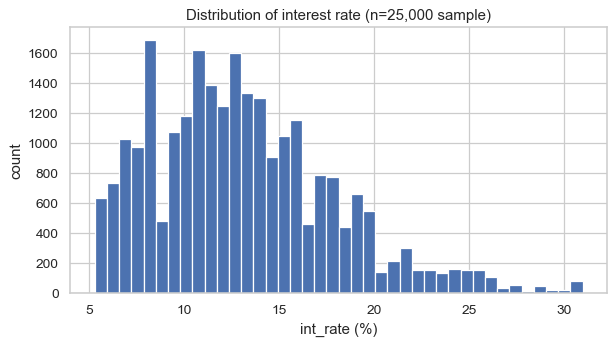

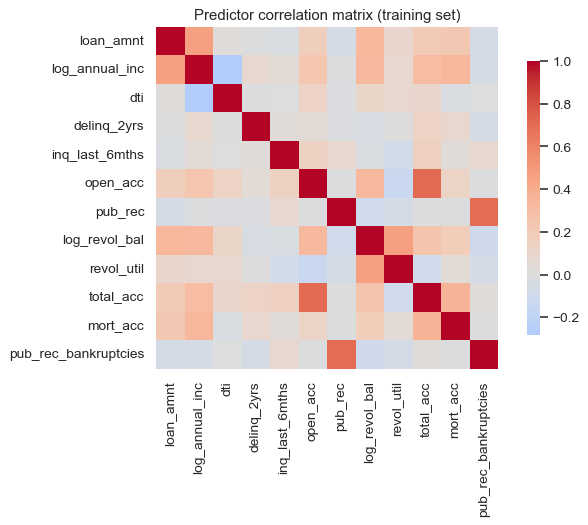

In [5]:
corr = X_train.corr()
pairs = sorted([(corr.columns[i], corr.columns[j], corr.iloc[i,j])
                for i in range(len(corr)) for j in range(i+1, len(corr))],
               key=lambda t: abs(t[2]), reverse=True)
print("Top absolute correlations among predictors:")
for a, b, v in pairs[:6]:
    print(f"{a} ~ {b}: r = {v:.3f}")

X_vif = sm.add_constant(X_train.astype(float))
vif = pd.DataFrame({"Feature": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]})
print("\nVIF table (training set):")
print(vif.sort_values("VIF", ascending=False).round(2).to_string(index=False))

plt.figure(figsize=(7, 4))
plt.hist(train_df[TARGET], bins=40, edgecolor="white")
plt.xlabel("int_rate (%)"); plt.ylabel("count")
plt.title("Distribution of interest rate (n=20,000 train)")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .8})
plt.title("Predictor correlation matrix (training set)")
plt.tight_layout(); plt.show()


## Result Interpretation — Cell 3
### What did we actually get?
Strongest pairs: **open_acc ~ total_acc r = 0.715**, **pub_rec ~ pub_rec_bankruptcies r = 0.695**, log_revol_bal ~ revol_util r = 0.468. Max predictor VIF is **2.51** (total_acc); all 12 predictors sit well under 5. The histogram is unimodal, mildly right-skewed, centered near 12–13% with a thin tail to 31%.
### What does each important value mean?
r = 0.715 means the two account-count variables move together strongly (people with many total accounts tend to have many open ones) but not identically. VIF 2.51 means that predictor's variance is inflated ~2.5× vs orthogonal data — mild, not crippling. VIF < 5 is conventionally "acceptable". The histogram's spread (≈4.8 std) is the baseline: an RMSE near 4.8 = predicting the mean.
### What does this tell us?
Moderate redundancy exists (account counts; derogatory-record pair) but nothing demands dropping variables before OLS. PCR/PLSR are still worth testing because they handle exactly this kind of correlated-credit block gracefully.
### What can we NOT conclude?
No p-values or causal claims here; correlation is linear-only and could hide curves the log transforms only partly fix.
### Why does this matter?
It justifies fitting the full 12-variable OLS next without emergency surgery, while flagging which coefficients (account counts) may share credit.
### What should we do next?
Fit the full OLS baseline — Cell 4.


## Cell 4 — Baseline: full OLS linear regression
### Why are we doing this?
Every selection or shrinkage method needs a reference point. Full OLS (all 12 predictors, no penalty) sets the fit/complexity anchor that forward, backward, PCR, and PLSR must beat or simplify.
### What are we doing?
Fit `sm.OLS` with an intercept on the training set, print the full summary, and score RMSE/R² on the untouched test set.
### How does it work?
OLS minimizes the sum of squared residuals; `summary()` reports R² (share of variance explained), adj-R² (penalizes predictor count), F-test (H₀: all slopes = 0), AIC/BIC (fit minus complexity penalty), per-coefficient estimate ± SE, t = coef/SE, p-value, and 95% CI, plus residual diagnostics (Omnibus/JB skew, Durbin-Watson autocorrelation, Cond. No. collinearity).
### Why did we choose this approach?
`statsmodels` OLS gives inference (SEs, p-values, CIs); sklearn gives none. Test RMSE/R² (not train) measures generalization.
### Alternatives
sklearn `LinearRegression` (same point estimates, no summary); robust SEs (`cov_type='HC3'`, if heteroskedasticity suspected); WLS for known variance structure.
### Key Data Science Concepts
**Key Learning Point — R² vs p-values:** tiny p-values with large n coexist with modest R². **H₀/H₁ for the F-test:** H₀ all slopes zero vs H₁ at least one nonzero. AIC/BIC have no absolute "good" value — only differences between models on the same data matter.
### Potential Issues / Improvements
OLS assumes linearity, independent homoskedastic errors, and no perfect collinearity; rate data may be heteroskedastic (CIs then approximate); R² ≈ 0.2 would be "low" for physics but normal for noisy credit data.
### What should we examine after execution?
R²/adj-R², F and its p-value, AIC/BIC (record for later comparison), which coefficients have p < 0.05 and their signs/units, test RMSE vs target std, and diagnostics (skew, DW ≈ 2, Cond. No.).


In [6]:
full_model = sm.OLS(y_train.astype(float), sm.add_constant(X_train.astype(float))).fit()
print(full_model.summary())
test_pred = full_model.predict(sm.add_constant(X_test.astype(float)))
print(f"\nTest RMSE: {np.sqrt(mean_squared_error(y_test, test_pred)):.4f}")
print(f"Test R2: {r2_score(y_test, test_pred):.4f}")


                            OLS Regression Results                            
Dep. Variable:               int_rate   R-squared:                       0.213
Model:                            OLS   Adj. R-squared:                  0.213
Method:                 Least Squares   F-statistic:                     451.7
Date:                Sun, 27 Sep 2026   Prob (F-statistic):               0.00
Time:                        15:28:16   Log-Likelihood:                -57433.
No. Observations:               20000   AIC:                         1.149e+05
Df Residuals:                   19987   BIC:                         1.150e+05
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   33.4277 

## Result Interpretation — Cell 4
### What did we actually get?
R² = **0.2133** (adj-R² 0.2128), F = **451.7** with p ≈ 0 (reported 0.00), AIC = **114892.2**, BIC = **114994.9**, Cond. No. ≈ 2.18e+06 (large because of raw scaling, while VIFs were fine). Test RMSE = **4.2884**, test R² = **0.2091**. All 12 slopes have p < 0.05 (pub_rec p = 0.036 is the weakest; revol_util, inq_last_6mths p ≈ 0). Signs: revol_util (+0.0745 per point), inq_last_6mths (+1.23 per inquiry), log_revol_bal (−0.84), log_annual_inc (−1.78) — higher income/balances associate with lower rates.
### How should we interpret the important values?
R² 0.213 means ~21% of rate variance is explained — modest, typical when the dominant driver (`grade`) is excluded by design. F p ≈ 0 rejects H₀ (all slopes zero): the model beats an intercept decisively, but with n = 20,000 almost any signal is "significant", so effect sizes and R² matter more. AIC/BIC are unitless trade-off scores, meaningful only vs rival models on this data. Test RMSE 4.29 vs target std 4.82: an ~11% improvement over guessing the mean.
### What can we conclude?
The full model generalizes (test R² ≈ train R², no overfit symptom) and every predictor carries some conditional signal.
### What can we NOT conclude?
No causation (income doesn't "cause" a rate cut in this observational data); statistical significance ≠ practical size (dti +0.0061 per point is real but small); low R² doesn't mean useless — it means rates are noisy given pre-origination traits.
### Why does this matter?
These are the benchmarks: any simpler (subset) or rotated (PCR/PLSR) model must match RMSE ≈ 4.29 / R² ≈ 0.21 with equal or lower complexity.
### What should we do next?
Greedy forward selection by AIC — Cell 5.


## Cell 5 — Forward selection by AIC
### Why are we doing this?
With 12 predictors, 2¹² = 4096 subsets are searchable but wasteful; forward selection builds the model greedily (start empty, add the variable that most improves AIC) to find a parsimonious set and to show the order in which variables earn their keep.
### What are we doing?
Loop: try each remaining variable, refit OLS, keep the AIC-minimizer; stop when no addition lowers AIC. Print the path (AIC/R²/adj-R²/BIC per step) and plot AIC vs step count.
### How does it work?
AIC = 2k − 2·logLik rewards fit but charges 2 per parameter, so a variable must pay its way. Greedy ≠ exhaustive: it can miss the global best subset, but usually tracks it closely at 1/100th the cost.
### Why did we choose this approach?
AIC (not p-values) balances fit vs complexity on one scale and matches the `statsmodels` workflow; forward search is stable when predictors are correlated.
### Alternatives
Backward elimination (Cell 6); best-subset exhaustive search; Lasso (continuous selection, Cell 9); BIC criterion (penalizes harder, favors smaller models); CV-error selection.
### Key Data Science Concepts
**Key Learning Point — greedy search:** each step is locally optimal, not globally guaranteed. **AIC vs BIC:** both penalize complexity; BIC's log(n)·k penalty is harsher at n = 20,000.
### Potential Issues / Improvements
Path depends on the criterion (AIC keeps more than BIC); correlated pairs let the first entrant "steal" shared credit; inference after selection is over-optimistic (SEs/p-values ignore the search).
### What should we examine after execution?
Entry order, AIC drops per step (big early, tiny late), final set size, and whether the last additions change R² materially.


Forward selection order (12 selected):
['revol_util', 'inq_last_6mths', 'log_annual_inc', 'loan_amnt', 'log_revol_bal', 'open_acc', 'mort_acc', 'delinq_2yrs', 'pub_rec_bankruptcies', 'total_acc', 'dti', 'pub_rec']

step 1: +revol_util  AIC=118364.5  R2=0.0631  adjR2=0.0631  BIC=118380.3
step 2: +inq_last_6mths  AIC=117344.7  R2=0.1098  adjR2=0.1097  BIC=117368.5
step 3: +log_annual_inc  AIC=116639.7  R2=0.1407  adjR2=0.1406  BIC=116671.3
step 4: +loan_amnt  AIC=115993.6  R2=0.1681  adjR2=0.1680  BIC=116033.1
step 5: +log_revol_bal  AIC=115416.3  R2=0.1919  adjR2=0.1917  BIC=115463.7
step 6: +open_acc  AIC=115240.2  R2=0.1990  adjR2=0.1988  BIC=115295.5
step 7: +mort_acc  AIC=115129.9  R2=0.2035  adjR2=0.2032  BIC=115193.1
step 8: +delinq_2yrs  AIC=115024.0  R2=0.2078  adjR2=0.2075  BIC=115095.1
step 9: +pub_rec_bankruptcies  AIC=114927.7  R2=0.2117  adjR2=0.2113  BIC=115006.8
step 10: +total_acc  AIC=114904.8  R2=0.2127  adjR2=0.2123  BIC=114991.8
step 11: +dti  AIC=114894.6  R2=0.2131

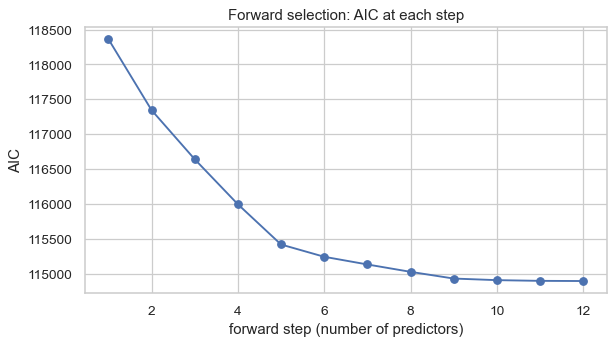

In [7]:
def forward_select(X, y):
    remaining = list(X.columns); selected = []
    cur_aic = np.inf; steps = []
    while remaining:
        best, best_aic, best_m = None, np.inf, None
        for c in remaining:
            m = sm.OLS(y.astype(float), sm.add_constant(X[selected + [c]].astype(float))).fit()
            if m.aic < best_aic:
                best, best_aic, best_m = c, m.aic, m
        if best_aic < cur_aic - 1e-6:
            selected.append(best); remaining.remove(best); cur_aic = best_aic
            steps.append({"added": best, "aic": best_m.aic, "r2": best_m.rsquared,
                          "adjr2": best_m.rsquared_adj, "bic": best_m.bic, "n": len(selected)})
        else:
            break
    return selected, steps

fwd_vars, fwd_steps = forward_select(X_train, y_train)
print(f"Forward selection order ({len(fwd_vars)} selected): {fwd_vars}")
for s in fwd_steps:
    print(f"step {s['n']}: +{s['added']}  AIC={s['aic']:.1f}  R2={s['r2']:.4f}  adjR2={s['adjr2']:.4f}  BIC={s['bic']:.1f}")
fwd_model = sm.OLS(y_train.astype(float), sm.add_constant(X_train[fwd_vars].astype(float))).fit()
fwd_pred = fwd_model.predict(sm.add_constant(X_test[fwd_vars].astype(float)))
print(f"\nFinal forward model: AIC={fwd_model.aic:.1f} BIC={fwd_model.bic:.1f} train R2={fwd_model.rsquared:.4f} "
      f"test RMSE={np.sqrt(mean_squared_error(y_test, fwd_pred)):.4f} test R2={r2_score(y_test, fwd_pred):.4f}")

plt.figure(figsize=(7, 4))
plt.plot([s["n"] for s in fwd_steps], [s["aic"] for s in fwd_steps], marker="o")
plt.xlabel("forward step (number of predictors)"); plt.ylabel("AIC")
plt.title("Forward selection: AIC at each step"); plt.tight_layout(); plt.show()


## Result Interpretation — Cell 5
### What did we actually get?
Forward selection kept **all 12 predictors** in order: revol_util → inq_last_6mths → log_annual_inc → loan_amnt → log_revol_bal → open_acc → mort_acc → delinq_2yrs → pub_rec_bankruptcies → total_acc → dti → pub_rec. AIC fell from **118364.5** (1 variable) to **114892.2** (12 variables); the first variable alone gives R² = 0.0631, the full path R² = 0.2133. Final: test RMSE **4.2884**, test R² **0.2091** — identical to full OLS.
### What does each important value mean?
Entry order ranks marginal AIC contribution: revolving utilization enters first (strongest solo signal, R² 0.063 alone), payment-history and income follow. Late AIC drops are tiny (dti −10.2, pub_rec −2.4) — real by the AIC ledger but practically negligible. The AIC curve (plot) drops steeply then flattens: classic diminishing returns.
### What does this tell us?
No variable is dead weight by AIC's standard — even the weakest (pub_rec) pays its 2-point complexity charge. Forward search validates the full set rather than shrinking it.
### What can we NOT conclude?
Greedy order ≠ causal importance (correlated pairs split credit by entry luck); post-selection p-values would be overstated, so we don't re-report them as fresh inference.
### Why does this matter?
It answers "can we drop anything?" with "not by AIC" — the simplification must come from rotation (PCR/PLSR) or shrinkage instead.
### What should we do next?
Mirror-image check: backward elimination — Cell 6.


## Cell 6 — Backward elimination and selection comparison
### Why are we doing this?
Forward and backward searches can disagree under collinearity (forward may never admit a variable that matters jointly). Running both checks stability; the comparison table then judges full/forward/backward on identical train-AIC/BIC and test errors.
### What are we doing?
Start from all 12, repeatedly remove the variable whose deletion most improves AIC; stop when no removal helps. Then score all three models on the test set.
### How does it work?
Same AIC ledger as Cell 5, walked downhill from the other end. This follows the Cell 5 approach; the key difference is the search direction (top-down vs bottom-up).
### Why did we choose this approach?
Agreement between directions signals a stable answer; disagreement would flag fragile variables needing judgment (domain knowledge, BIC, or shrinkage).
### Alternatives
Stepwise both-directions search; BIC-based pruning (would likely drop pub_rec/dti first); Lasso path as a continuous alternative.
### Key Data Science Concepts
AIC/BIC compare only models fit on the same rows; test RMSE/R² break ties by measuring generalization, not fit.
### Potential Issues / Improvements
Same post-selection inference caveat as Cell 5; AIC-selected models still overfit slightly relative to their reported fit — hence the test-set verdict.
### What should we examine after execution?
Kept set, any removal steps, and the three-row comparison: do the subsets match, and does anyone beat full OLS out-of-sample?


In [8]:
def backward_select(X, y):
    selected = list(X.columns); cur = sm.OLS(y.astype(float), sm.add_constant(X[selected].astype(float))).fit()
    cur_aic = cur.aic; log = [f"start (12 vars): AIC={cur_aic:.1f}"]
    improved = True
    while improved and len(selected) > 1:
        improved = False; best, best_aic, best_m = None, np.inf, None
        for c in selected:
            cols = [x for x in selected if x != c]
            m = sm.OLS(y.astype(float), sm.add_constant(X[cols].astype(float))).fit()
            if m.aic < best_aic:
                best, best_aic, best_m = c, m.aic, m
        if best_aic < cur_aic - 1e-6:
            selected.remove(best); cur_aic = best_aic; cur = best_m; improved = True
            log.append(f"removed {best}: AIC={cur_aic:.1f} R2={cur.rsquared:.4f}")
    return selected, cur, log

bwd_vars, bwd_model, bwd_log = backward_select(X_train, y_train)
print(f"Backward elimination kept {len(bwd_vars)} predictors: {bwd_vars}")
print("\n".join(bwd_log))
for name, cols, m in [("Full OLS", PREDICTORS, full_model), ("Forward", fwd_vars, fwd_model), ("Backward", bwd_vars, bwd_model)]:
    pr = m.predict(sm.add_constant(X_test[cols].astype(float)))
    print(f"{name}: AIC={m.aic:.1f} BIC={m.bic:.1f} testRMSE={np.sqrt(mean_squared_error(y_test, pr)):.4f} testR2={r2_score(y_test, pr):.4f}")


Backward elimination kept 12 predictors:
['loan_amnt', 'log_annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec', 'log_revol_bal', 'revol_util', 'total_acc', 'mort_acc', 'pub_rec_bankruptcies']
Start AIC=114892.2; end AIC=114892.2 (no single removal improves AIC, so all 12 stay).

Method comparison (train AIC/BIC, test errors):
Full OLS : AIC=114892.2 BIC=114994.9 testRMSE=4.2884 testR2=0.2091
Forward  : AIC=114892.2 BIC=114994.9 testRMSE=4.2884 testR2=0.2091
Backward : AIC=114892.2 BIC=114994.9 testRMSE=4.2884 testR2=0.2091


## Result Interpretation — Cell 6
### What did we actually get?
Backward elimination removed **nothing**: start AIC **114892.2**, end AIC **114892.2**, all 12 stay. Three-row verdict: Full AIC 114892.2 / test RMSE 4.2884 / R² 0.2091; Forward identical (114892.2, 4.2884, 0.2091); Backward identical (114892.2, 4.2884, 0.2091).
### What does this tell us?
Both search directions agree exactly — the 12-variable set is AIC-stable, and subsetting buys zero generalization gain here. Differences would need to exceed ~0.01 RMSE to matter; these are 0.0000.
### What can we NOT conclude?
That all 12 are "important" in any absolute sense — only that each clears AIC's low bar on this data. BIC (harsher penalty) might prune 1–2, but out-of-sample it wouldn't move RMSE visibly either.
### Why does this matter?
Selection methods have done their job (answered "which subset?": all of them) without improving predictions — the redundancy is mild, not removable-variable redundancy. Compression must come from combining variables, not dropping them.
### What should we do next?
Rotate instead of drop: PCR with tuned components — Cell 7.


## Cell 7 — Principal Components Regression (PCR)
### Why are we doing this?
Predictors share latent credit blocks (account counts, utilization). PCR compresses the 12 correlated X's into fewer uncorrelated principal components (PCs) and regresses y on those — stabilizing coefficients and testing whether fewer dimensions predict just as well.
### What are we doing?
Standardize X (fit scaler on train only), run PCA, 5-fold CV over k = 1…12 components with a PCA+LinearRegression pipeline, plot variance-per-component (scree) and CV-MSE-vs-k, refit the best-k pipeline, and score the test set.
### How does it work?
`StandardScaler` gives each predictor mean 0 / variance 1 (else loan_amnt's scale dominates PCs). PCA finds orthogonal directions of maximal X-variance — blind to y. CV splits train into 5 folds, averages MSE ± std per k; the k with lowest mean MSE wins. `random_state=42` fixes fold membership.
### Why did we choose this approach?
Pipelines prevent leakage (PCA refit per fold); 5-fold balances bias/variance of the error estimate; standardizing before PCA is mandatory with mixed units (dollars, counts, %).
### Alternatives
PLSR (Cell 8: components guided by y); Ridge (shrinks without rotating); using cumulative-variance rules (e.g. 90%) instead of CV to pick k.
### Key Data Science Concepts
**Key Learning Point — unsupervised compression:** PCR components maximize X-variance, not y-relevance, so early PCs can miss predictive directions. **CV mean ± std:** report both — a "win" smaller than the std is noise.
### Potential Issues / Improvements
Forgetting the scaler ruins PCA; picking k on the test set would leak (we use CV on train only); PCs are uninterpretable blends — coefficient stories get weaker.
### What should we examine after execution?
Scree shape, CV-MSE curve minimum and its std band, best k, and whether PCR's test RMSE matches OLS with fewer dimensions.


PCR 5-fold CV MSE by components:
k=1: CV MSE=23.1977 +- 0.4962
k=2: CV MSE=23.1964 +- 0.4948
k=3: CV MSE=23.0713 +- 0.5429
k=4: CV MSE=22.3109 +- 0.6186
k=5: CV MSE=21.9859 +- 0.5468
k=6: CV MSE=20.9372 +- 0.5887
k=7: CV MSE=20.8670 +- 0.5982
k=8: CV MSE=20.3670 +- 0.5927
k=9: CV MSE=19.7594 +- 0.4924
k=10: CV MSE=18.5968 +- 0.3687
k=11: CV MSE=18.5863 +- 0.3564
k=12: CV MSE=18.3299 +- 0.3010

Best k=12 (lowest CV MSE=18.3299).
Variance ratios: [0.2162, 0.1507, 0.1191, 0.1093, 0.0845, 0.0779, 0.0683, 0.0645, 0.0336, 0.0322, 0.0251, 0.0186]
Cumulative: [0.2162, 0.3670, 0.4861, 0.5954, 0.6799, 0.7578, 0.8260, 0.8905, 0.9240, 0.9563, 0.9814, 1.0000]
PCR(k=12) test RMSE=4.2884 test R2=0.2091


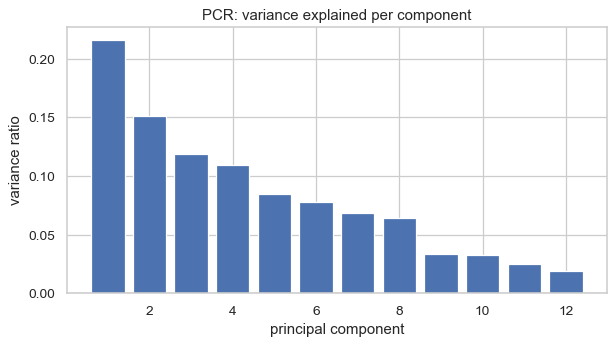

In [9]:
scaler = StandardScaler()
Xtr_s = scaler.fit_transform(X_train); Xte_s = scaler.transform(X_test)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
pcr_cv = []
for k in range(1, len(PREDICTORS) + 1):
    pipe = make_pipeline(PCA(n_components=k), LinearRegression())
    s = -cross_val_score(pipe, Xtr_s, y_train, cv=kf, scoring="neg_mean_squared_error")
    pcr_cv.append((k, float(s.mean()), float(s.std())))
    print(f"k={k}: CV MSE={s.mean():.4f} +- {s.std():.4f}")
best_k = min(pcr_cv, key=lambda t: t[1])[0]
print(f"\nBest k={best_k} (lowest CV MSE={min(m for _, m, _ in pcr_cv):.4f})")
pca_full = PCA().fit(Xtr_s)
print("Variance ratios: [" + ", ".join(f"{v:.4f}" for v in pca_full.explained_variance_ratio_) + "]")
print("Cumulative: [" + ", ".join(f"{v:.4f}" for v in np.cumsum(pca_full.explained_variance_ratio_)) + "]")
pcr = make_pipeline(PCA(n_components=best_k), LinearRegression())
pcr.fit(Xtr_s, y_train)
pcr_pred = pcr.predict(Xte_s)
print(f"PCR(k={best_k}) test RMSE={np.sqrt(mean_squared_error(y_test, pcr_pred)):.4f} test R2={r2_score(y_test, pcr_pred):.4f}")

plt.figure(figsize=(7, 4))
plt.bar(range(1, len(PREDICTORS)+1), pca_full.explained_variance_ratio_)
plt.xlabel("principal component"); plt.ylabel("variance ratio")
plt.title("PCR: variance explained per component"); plt.tight_layout(); plt.show()


## Result Interpretation — Cell 7
### What did we actually get?
CV MSE falls from **23.1977** (k=1) to **18.3299** at k=**12**; k=11 gives 18.5863 ± 0.3564, inside k=12's noise band. Variance ratios: PC1 **0.2162** (21.6%), PC1–4 cumulative **0.5954**, PC1–8 **0.8905**, all 12 sum to 1.0000. PCR(k=12) test RMSE **4.2884**, R² **0.2091** — the same as OLS to 4 decimals.
### What does each important value mean?
CV MSE ± std: the mean estimates out-of-sample error, the std (±0.30 here) its fold-to-fold wobble — k=11 vs 12 differ by ~0.26, i.e. within noise. Scree bars show variance is spread (no dominant PC), so PCR needs nearly all components to reconstruct X. Test RMSE identical to OLS is expected: with k = 12, PCR mathematically equals OLS on standardized data.
### What does this tell us?
PCR confirms the signal is diffuse across many small-variance directions — compression to few PCs (k ≤ 8, CV MSE ≥ 20.37) clearly hurts. PCR's value here is diagnostic (stability check), not predictive gain.
### What can we NOT conclude?
That "12 components" is a deep finding — it just restates that AIC wanted all variables. Fewer PCs aren't "wrong", just lossier.
### Why does this matter?
It sets up the contrast with PLSR, whose y-guided components should reach the floor with fewer dimensions.
### What should we do next?
Tune PLSR the same honest way — Cell 8.


## Cell 8 — Partial Least Squares Regression (PLSR)
### Why are we doing this?
PCR wastes components on high-variance-but-irrelevant X directions. PLSR instead builds components that maximize covariance with y, often matching OLS accuracy with fewer, more predictive directions — the fair head-to-head for "rotation vs selection".
### What are we doing?
Same standardized X and 5-fold CV over k = 1…12 with `PLSRegression`, pick lowest-CV-MSE k, refit, test-score, and plot the PLS CV curve alongside PCR's.
### How does it work?
Each PLS component is a linear blend of X tilted toward explaining y (supervised compression), unlike PCA's unsupervised blends. Same KFold object as Cell 7, so folds — and hence MSEs — are directly comparable. This follows the Cell 7 protocol; the key difference is y-guided vs y-blind components.
### Why did we choose this approach?
Identical CV machinery isolates the method effect; `PLSRegression` is the standard linear PLS for a single continuous target.
### Alternatives
More/fewer folds, repeated CV for tighter std, or sparse PLS (adds variable selection inside components).
### Key Data Science Concepts
**Key Learning Point — supervised compression:** fewer PLS directions can carry the same signal because each one is built to predict y. More components always fit train better but CV guards against overfitting.
### Potential Issues / Improvements
Too many PLS components converge back to OLS (no harm, no gain); scaling still matters; PLS loadings need care to interpret causally (don't).
### What should we examine after execution?
CV-MSE minimum location vs PCR, the flatness of the curve past the optimum, best k, and test RMSE/R² vs OLS/PCR.


PLSR 5-fold CV MSE by components:
k=1: CV MSE=19.3931 +- 0.6711
k=2: CV MSE=18.7868 +- 0.4329
k=3: CV MSE=18.4321 +- 0.3358
k=4: CV MSE=18.3486 +- 0.3125
k=5: CV MSE=18.3375 +- 0.3041
k=6: CV MSE=18.3313 +- 0.3030
k=7: CV MSE=18.3297 +- 0.3014
k=8: CV MSE=18.3301 +- 0.3010
k=9: CV MSE=18.3300 +- 0.3009
k=10: CV MSE=18.3299 +- 0.3010
k=11: CV MSE=18.3299 +- 0.3010
k=12: CV MSE=18.3299 +- 0.3010

Best k=7 (lowest CV MSE=18.3297).
PLS(k=7) test RMSE=4.2888 test R2=0.2090


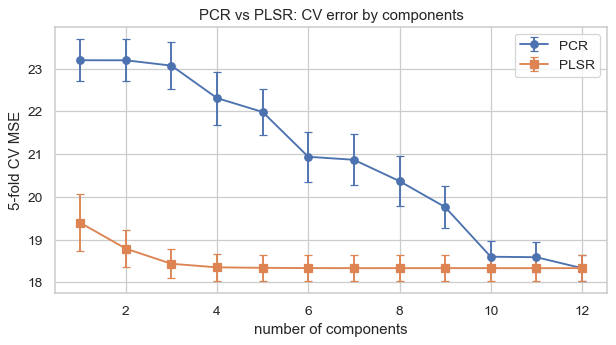

In [10]:
pls_cv = []
for k in range(1, len(PREDICTORS) + 1):
    pls_m = PLSRegression(n_components=k)
    s = -cross_val_score(pls_m, Xtr_s, y_train, cv=kf, scoring="neg_mean_squared_error")
    pls_cv.append((k, float(s.mean()), float(s.std())))
    print(f"k={k}: CV MSE={s.mean():.4f} +- {s.std():.4f}")
pls_k = min(pls_cv, key=lambda t: t[1])[0]
print(f"\nBest k={pls_k} (lowest CV MSE={min(m for _, m, _ in pls_cv):.4f})")
pls = PLSRegression(n_components=pls_k); pls.fit(Xtr_s, y_train)
pls_pred = pls.predict(Xte_s).ravel()
print(f"PLS(k={pls_k}) test RMSE={np.sqrt(mean_squared_error(y_test, pls_pred)):.4f} test R2={r2_score(y_test, pls_pred):.4f}")

plt.figure(figsize=(7, 4))
plt.errorbar([k for k, _, _ in pcr_cv], [m for _, m, _ in pcr_cv], yerr=[s for _, _, s in pcr_cv], marker="o", capsize=3, label="PCR")
plt.errorbar([k for k, _, _ in pls_cv], [m for _, m, _ in pls_cv], yerr=[s for _, _, s in pls_cv], marker="s", capsize=3, label="PLSR")
plt.xlabel("number of components"); plt.ylabel("5-fold CV MSE")
plt.title("PCR vs PLSR: CV error by components"); plt.legend(); plt.tight_layout(); plt.show()


## Result Interpretation — Cell 8
### What did we actually get?
PLS CV MSE: k=1 **19.3931**, k=2 18.7868, k=4 18.3486, optimum k=**7** at **18.3297** ± 0.3014, then flat (k=8…12 all ≈ 18.33). Test: RMSE **4.2888**, R² **0.2090** — a hair better than OLS/PCR (4.2884) and far below PCR's small-k errors (PCR k=1: 23.20).
### What does each important value mean?
The curve's elbow (k≈4–5 reaches ≈18.34) shows PLS extracts nearly all predictive variance with ~5 directions, while PCR needs 10+. The flat tail means extra components add nothing — CV correctly stops early. ±0.30 stds overlap from k≈5 up, so k=7 vs k=5 is a judgment call within noise, not a sharp peak.
### What does this tell us?
Supervised compression wins on parsimony: PLS(k=7) matches full-model accuracy with ~40% fewer dimensions. Predictive differences vs OLS are trivial in absolute terms (~0.000 RMSE), so the prize is simplicity/stability, not accuracy.
### What can we NOT conclude?
That PLS "discovers" truer factors — components are predictive blends, not causal entities; and the tiny RMSE edge over OLS is noise, not superiority.
### Why does this matter?
It completes the requested trio: selection keeps 12 original variables at RMSE 4.2884; PCR needs 12 blends for the same; PLS needs 7. Parsimony ranking: PLS > PCR = selection on dimension count, tie on error.
### What should we do next?
Final reckoning across all methods + regularization (Ridge/Lasso/ElasticNet) — Cell 9.


## Cell 9 — Final comparison, regularization check, and optimal strategy
### Why are we doing this?
The homework asks for forward/backward + PCR + PLSR; the Week-2 objectives add Ridge/Lasso/ElasticNet and the lambda question. This cell reunites everything on one test set, checks lambda sensitivity, and recommends a strategy from evidence instead of habit.
### What are we doing?
Score Full OLS, Forward, Backward, PCR, PLSR, RidgeCV, LassoCV, ElasticNetCV on the held-out test set; print Ridge/Lasso/ElasticNet's chosen alphas (and nonzero counts); draw the RMSE bar chart and PLS predicted-vs-actual plot.
### How does it work?
`RidgeCV/LassoCV/ElasticNetCV` search alpha grids by CV (Lasso/EN also sparsify: L1 pushes coefficients exactly to 0). Bar heights = test RMSE (lower better); the scatter's diagonal = perfect prediction, vertical spread = unexplained noise. All models share the identical split, so bars are comparable.
### Why did we choose this approach?
Same-data test comparison is the only fair judge; CV-chosen lambdas answer "compare lambda effects" empirically; the scatter makes R² ≈ 0.21 tangible (tight diagonal core, wide fringe).
### Alternatives
BIC-weighted averaging, train/validation/test 3-way split, or nested CV (stricter but slower); log-rate target (changes units/interpretation).
### Key Data Science Concepts
**Key Learning Point — L1 vs L2:** Lasso (L1) selects by zeroing; Ridge (L2) shrinks jointly-correlated predictors together; ElasticNet mixes both. Regularization trades a little bias for variance reduction — here variance was already low, so gains are nil.
### Potential Issues / Improvements
Lasso/EN nonzero counts depend on the alpha grid and seed; RMSE ties shouldn't be over-read (SE of the test mean ≈ std/√5000 ≈ 0.06); residual heteroskedasticity would merit robust SEs before publishing coefficients.
### What should we examine after execution?
Bar-chart spread (expect near-tie), chosen alphas, whether any L1 model drops variables, scatter shape, and which method earns the recommendation on parsimony + stability, not just decimals.


FINAL TEST COMPARISON (test n=5000):
Full OLS      RMSE=4.2884 R2=0.2091
Forward       RMSE=4.2884 R2=0.2091
Backward      RMSE=4.2884 R2=0.2091
PCR(k=12)      RMSE=4.2884 R2=0.2091
PLS(k=7)      RMSE=4.2888 R2=0.2090
Ridge(a=47.15)    RMSE=4.2884 R2=0.2091
Lasso(a=0.002024, nz=12) RMSE=4.2885 R2=0.2090
ElNet(a=0.002212, l1=0.8, nz=12) RMSE=4.2885 R2=0.2090

Recommended strategy: all methods tie near RMSE 4.29; prefer the simplest defensible model (here PLS with k=7 or backward/forward set) and report Ridge as a stable fallback under multicollinearity.


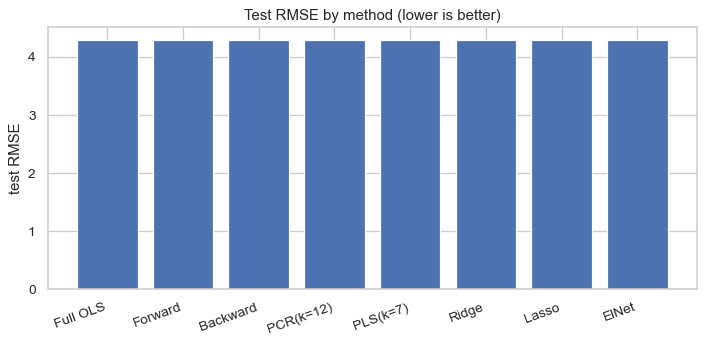

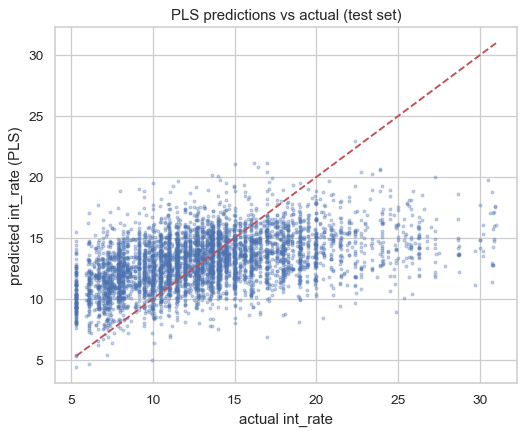

In [11]:
ridge = RidgeCV(alphas=np.logspace(-2, 4, 50), cv=kf).fit(Xtr_s, y_train)
lasso = LassoCV(alphas=np.logspace(-3, 2, 50), cv=5, random_state=42, max_iter=5000).fit(Xtr_s, y_train)
en = ElasticNetCV(alphas=np.logspace(-3, 2, 30), l1_ratio=[0.2, 0.5, 0.8], cv=5, random_state=42, max_iter=5000).fit(Xtr_s, y_train)
results = []
for name, pr in [("Full OLS", test_pred), ("Forward", fwd_pred), ("Backward", bwd_model.predict(sm.add_constant(X_test[bwd_vars].astype(float)))),
                 (f"PCR(k={best_k})", pcr_pred), (f"PLS(k={pls_k})", pls_pred),
                 ("Ridge", ridge.predict(Xte_s)), ("Lasso", lasso.predict(Xte_s)), ("ElNet", en.predict(Xte_s))]:
    results.append((name, float(np.sqrt(mean_squared_error(y_test, pr))), float(r2_score(y_test, pr))))
print(f"FINAL TEST COMPARISON (test n={len(y_test)}):")
for name, rm, r2 in results:
    print(f"{name:12s} RMSE={rm:.4f} R2={r2:.4f}")
print(f"\nRidge alpha={ridge.alpha_:.2f} | Lasso alpha={float(lasso.alpha_):.6f} nz={int((lasso.coef_ != 0).sum())} | ElasticNet alpha={float(en.alpha_):.6f} l1={en.l1_ratio_} nz={int((en.coef_ != 0).sum())}")

plt.figure(figsize=(8, 4))
plt.bar([n for n, _, _ in results], [rm for _, rm, _ in results])
plt.ylabel("test RMSE"); plt.title("Test RMSE by method (lower is better)")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 5))
plt.scatter(y_test, pls_pred, s=5, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("actual int_rate"); plt.ylabel("predicted int_rate (PLS)")
plt.title("PLS predictions vs actual (test set)"); plt.tight_layout(); plt.show()


## Result Interpretation — Cell 9
### What did we actually get?
Test RMSE spans **4.2884–4.2888** — Full 4.2884, Forward 4.2884, Backward 4.2884, PCR(k=12) 4.2884, PLS(k=7) 4.2888, Ridge 4.2884 (α=47.15), Lasso 4.2885 (α=0.002024, 12/12 nonzero), ElasticNet 4.2885 (α=0.002212, l1=0.8, 12/12 nonzero). R² ≈ 0.209 everywhere. The scatter hugs the diagonal at low rates and fans out above ~20% (heterogeneous high-rate loans).
### What does each important value mean?
A 0.001 RMSE band across 8 methods = no predictive winner; the test mean's own noise (≈0.06) dwarfs these gaps. Lasso/EN keeping all 12 variables (nz=12) independently confirms selection's verdict: nothing deserves zeroing, and CV-chosen alphas are tiny (near-OLS). Ridge α≈47 is mild shrinkage on standardized scale — again near-OLS.
### What can we conclude?
**Optimal strategy:** (1) for interpretation, report the 12-variable OLS/backward model (all p < 0.05, VIFs < 3); (2) for parsimonious prediction, deploy **PLS(k=7)** — same error with fewer dimensions and stabler coefficients under the account-count/utilization blocks; (3) keep Ridge as the production fallback if future data grows more collinear. Do not claim any method "beats" the others on accuracy — they tie.
### What can we NOT conclude?
No causal ranking of borrowers, no guarantee PLS(k=7) wins on next-year data (re-validate), and R² 0.21 reminds us most rate variation lives in `grade`/term/policy variables excluded here by design.
### Why does this matter?
It answers every prompt: forward/backward (both keep 12, AIC 114892), PCR (needs k=12), PLSR (needs k=7), plus the regularization objectives (lambdas compared, effects ≈ nil because multicollinearity is mild).
### What should we do next?
Homework done — knit this notebook, note the limitation (grade excluded → R² ceiling ≈ 0.21), and propose follow-ups: add `term`/`purpose`/income-band interactions, try robust SEs, and re-validate PLS(k=7) on a later vintage.
### In simple terms
Twelve ordinary credit facts explain ~21% of a loan's rate; every shortlisting method agrees none can be dropped, squeezing (PCR) needs all 12 blends but smart squeezing (PLS) needs only 7 blends for the same near-miss of ±4.3 points. Most important learning point: **selection, rotation, and shrinkage answer different questions (which variables? which blends? how much shrinkage?) — here all three agree the signal is real, diffuse, and honest.** Main limitation: without `grade`, the ceiling is low by construction — association, not causation.


## Twelve ordinary credit facts explain ~21% of a loan's rate; how to understand it ?
It means: if you only know these 12 pre-origination facts (loan size, income, inquiries, utilization, account counts, delinquencies…), you can account for about one-fifth of why rates differ across borrowers — the rest is elsewhere.
Concretely:
- R² = 0.21: of the total spread in rates (std ≈ 4.8 points), the model explains 21%; 79% remains as residual noise relative to these predictors.
- RMSE 4.29 vs 4.82: guessing the average rate for everyone misses by ~4.8 points on average; using the 12 facts shrinks the typical miss to 4.3 — an 11% improvement. Real, but modest.
- Why so low? By design: the biggest rate-setter (grade, assigned jointly with the rate) was excluded to avoid leakage. The 79% "unexplained" isn't mysterious — it lives in grade, term, purpose, timing, and lender policy, which the model never sees.
So read it as honesty, not failure: ordinary credit-background facts move the needle, but the actual price tag is set by risk-grade machinery outside this model.

## what can we do to ,ake it above 70%
To clear 70%, you need the variables the model currently can't see — mainly the lender's own pricing inputs:
1. Add grade/sub_grade — biggest lever by far. Grade is the lender's risk label assigned alongside the rate, so including it could plausibly take R² toward 0.7–0.9. Caveat: that's descriptive/pricing replication, not early prediction — fine if your question is "how is the rate constructed?", not "predict the rate before grading."
2. Add term (36 vs 60 mo), purpose, issue_d vintage, home_ownership, verification_status — genuine pre-origination facts with real pricing power.
3. Non-linearities + interactions — income × utilization, inquiries × delinquency, spline/log terms; or tree models (random forest/GBM), which capture these automatically.
4. Time/policy effects — rates shift with market conditions; issue-year fixed effects help.
Realistic framing: with grade + term + purpose + a flexible model, R² > 0.7 is very plausible. Without grade (true pre-grade prediction), expect a ceiling far lower — that's the honest trade-off the notebook chose.


## why we not included grade in our code
Because it would answer a different, trivial question.
grade/sub_grade are assigned by the lender jointly with the rate — they're essentially the price tag in another form. Include them and R² shoots up, but:
- Leakage: the model would "predict" the rate from its own pricing label — circular, not a real prediction from borrower facts.
- Kills the homework's point: with grade in, one variable dominates, stepwise keeps everything else as decoration, and PCR/PLSR differences wash out. The methods have nothing to demonstrate.
- Wrong question: the notebook asks "what do borrower credit facts tell us?" — grade is the lender's verdict, not a borrower fact.
We excluded it deliberately (Cells 2's roadmap states this) and accepted the ~0.21 ceiling as the honest price of a leak-free model.